In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/processed")

orders = pd.read_csv(data_path / "orders.csv")
items = pd.read_csv(data_path / "order_items.csv")
products = pd.read_csv(data_path / "products.csv")

print("Orders:", orders.shape)
print("Order items:", items.shape)
print("Products:", products.shape)

Orders: (100000, 16)
Order items: (254331, 9)
Products: (550, 14)


In [2]:
print("Orders:", orders.columns.tolist())
print("Items:", items.columns.tolist())
print("Products:", products.columns.tolist())

Orders: ['order_id', 'customer_id', 'order_date', 'order_time', 'order_status', 'shipping_method', 'delivery_city', 'delivery_state', 'coupon_code', 'discount_percentage', 'marketing_channel', 'subtotal', 'shipping_fee', 'tax_amount', 'final_amount', 'campaign_id']
Items: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'item_revenue', 'item_cost', 'profit']
Products: ['product_id', 'product_name', 'category', 'subcategory', 'brand', 'price', 'cost_price', 'discount_range', 'rating_average', 'rating_count', 'stock_quantity', 'product_launch_date', 'product_type', 'return_rate_baseline']


In [3]:
valid_orders = orders.loc[
    orders["order_status"] == "Delivered", ["order_id", "customer_id"]
]

purchase_data = items.merge(valid_orders, on="order_id", how="inner")

purchase_data = purchase_data.merge(
    products[["product_id", "product_name", "category"]],
    on="product_id",
    how="left"
)

print("Purchase rows:", len(purchase_data))
purchase_data.head()

Purchase rows: 205224


,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit,customer_id,product_name,category
0,OI10000005,ORD1000001,PROD10092,5,920.0,15.0,3910.0,3811.90,98.10,CUST118472,"Mittal, Premium Snack",Grocery
1,OI10000006,ORD1000001,PROD10114,2,500.0,15.0,850.0,764.82,85.18,CUST118472,Handa Pro Filing & Storage,Office Supplies
2,OI10000007,ORD1000002,PROD10470,2,590.0,30.0,826.0,712.38,113.62,CUST120793,Barad-Singhal Ultra Sports Shoe,Footwear
3,OI10000012,ORD1000005,PROD10085,2,870.0,8.0,1600.8,1292.08,308.72,CUST123408,Khatri-Bhardwaj Deluxe Office Stationery,Stationery
4,OI10000013,ORD1000005,PROD10233,1,3440.0,8.0,3164.8,2676.46,488.34,CUST123408,Soman Essential Cookware,Home & Kitchen


In [4]:
product_summary = purchase_data.groupby(
    ["product_id", "product_name", "category"]
).agg(
    units_sold=("quantity", "sum"),
    order_count=("order_id", "nunique"),
    customers=("customer_id", "nunique")
).sort_values("order_count", ascending=False)

product_summary.head(10)

,,,units_sold,order_count,customers
product_id,product_name,category,,,
PROD10403,Chanda Deluxe Winter Wear,Fashion,14178,5946,4943
PROD10341,"Solanki, Basic Winter Wear",Fashion,11704,4957,4282
PROD10112,Soman Classic Comic,Books,10493,4448,3863
PROD10101,"Memon, Compact Action Figure",Toys,9660,4120,3622
PROD10392,Gandhi-Lanka Ultra Storage & Container,Home & Kitchen,8948,3795,3347
PROD10417,Goda Ultra Air Conditioner,Appliances,8678,3742,3318
PROD10031,Shah Basic Handbag,Bags,8915,3740,3336
PROD10203,"Mistry, Basic Large Appliance",Appliances,8117,3504,3130
PROD10488,Kar-Issac Premium Kids Wear,Fashion,7944,3375,3011


In [5]:
basket = purchase_data.pivot_table(
    index="order_id",
    columns="product_id",
    values="quantity",
    aggfunc="sum",
    fill_value=0
)

basket.head()

product_id,PROD10000,PROD10001,PROD10002,PROD10003,PROD10004,PROD10005,PROD10006,PROD10007,PROD10008,PROD10009,...,PROD10540,PROD10541,PROD10542,PROD10543,PROD10544,PROD10545,PROD10546,PROD10547,PROD10548,PROD10549
order_id,,,,,,,,,,,,,,,,,,,,,
ORD1000001,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ORD1000002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ORD1000005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ORD1000006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ORD1000008,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
basket_binary = (basket > 0).astype("int8")
co_purchase = basket_binary.T.dot(basket_binary)

co_purchase.head()

product_id,PROD10000,PROD10001,PROD10002,PROD10003,PROD10004,PROD10005,PROD10006,PROD10007,PROD10008,PROD10009,...,PROD10540,PROD10541,PROD10542,PROD10543,PROD10544,PROD10545,PROD10546,PROD10547,PROD10548,PROD10549
product_id,,,,,,,,,,,,,,,,,,,,,
PROD10000,109,0,0,0,0,1,1,2,1,0,...,0,1,1,0,0,0,0,0,1,0
PROD10001,0,62,0,0,0,0,0,0,0,0,...,0,2,0,0,1,0,0,0,1,0
PROD10002,0,0,-81,0,1,1,1,2,1,0,...,0,4,0,0,1,0,0,1,1,1
PROD10003,0,0,0,86,1,1,1,1,0,0,...,0,1,0,0,0,0,0,0,0,1
PROD10004,0,0,1,1,44,2,1,10,0,0,...,3,10,1,2,0,1,2,2,4,3


In [8]:
def recommend_products(product_id, top_n=5):
    if product_id not in co_purchase.columns:
        return pd.DataFrame(columns=["product_id", "product_name", "category", "co_orders"])

    scores = co_purchase[product_id].drop(product_id)
    scores = scores[scores > 0].sort_values(ascending=False).head(top_n)

    recommendations = scores.rename("co_orders").reset_index()
    recommendations = recommendations.merge(
        products[["product_id", "product_name", "category"]],
        on="product_id",
        how="left"
    )

    return recommendations[["product_id", "product_name", "category", "co_orders"]]

In [9]:
popular_product_id = product_summary.index.get_level_values("product_id")[0]

print("Selected product:", popular_product_id)
recommend_products(popular_product_id, top_n=5)

Selected product: PROD10403


,product_id,product_name,category,co_orders
0,PROD10035,Sankar Basic Supplement,Health & Wellness,127
1,PROD10327,"Murty, Pro Sports Shoe",Footwear,123
2,PROD10499,"Konda, Premium Bedding",Home & Kitchen,122
3,PROD10051,Ramakrishnan Advanced Winter Wear,Fashion,121
4,PROD10078,"Sunder, Classic Women's Western Wear",Fashion,106


In [10]:
customer_history = purchase_data.groupby("customer_id").agg(
    orders=("order_id", "nunique"),
    products_bought=("product_id", "nunique")
).sort_values("orders", ascending=False)

customer_history.head(10)

,orders,products_bought
customer_id,,
CUST104958,22,52
CUST107174,20,46
CUST111225,19,44
CUST118509,19,43
CUST123291,19,48
CUST115716,19,49
CUST115935,19,40
CUST102476,18,43
CUST119962,18,48


In [11]:
def recommend_for_customer(customer_id, top_n=5):
    bought = purchase_data.loc[
        purchase_data["customer_id"] == customer_id, "product_id"
    ].unique()

    scores = co_purchase.loc[
        co_purchase.index.isin(bought), :
    ].sum(axis=0)

    scores = scores.drop(labels=bought, errors="ignore")
    scores = scores[scores > 0].sort_values(ascending=False).head(top_n)

    result = scores.rename("recommendation_score").reset_index()
    result = result.merge(
        products[["product_id", "product_name", "category"]],
        on="product_id",
        how="left"
    )

    return result[["product_id", "product_name", "category", "recommendation_score"]]

In [12]:
sample_customer = purchase_data["customer_id"].iloc[0]

print("Customer:", sample_customer)
recommend_for_customer(sample_customer, top_n=5)

Customer: CUST118472


,product_id,product_name,category,recommendation_score
0,PROD10341,"Solanki, Basic Winter Wear",Fashion,228
1,PROD10035,Sankar Basic Supplement,Health & Wellness,191
2,PROD10499,"Konda, Premium Bedding",Home & Kitchen,183
3,PROD10112,Soman Classic Comic,Books,180
4,PROD10051,Ramakrishnan Advanced Winter Wear,Fashion,179


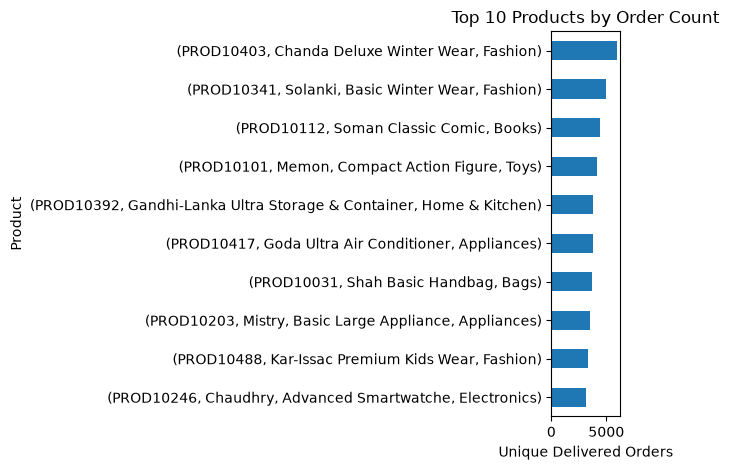

In [13]:
import matplotlib.pyplot as plt

product_summary["order_count"].head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Order Count")
plt.xlabel("Unique Delivered Orders")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [14]:
output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

product_summary.to_csv(output_path / "product_summary.csv")

sample_recommendations = recommend_for_customer(sample_customer, top_n=10)
sample_recommendations.to_csv(
    output_path / "sample_recommendations.csv", index=False
)

print("Product summary and sample recommendations saved.")

Product summary and sample recommendations saved.


In [15]:
co_purchase.to_csv(output_path / "product_co_purchase.csv")
print("Co-purchase matrix saved.")

Co-purchase matrix saved.
